# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Our data: load and clean

The TODOs below run on the real project files in `data/`, not the toy frames above. This cell is the cleaning pipeline in compact form: every decision that removes rows is logged with its row count.

**Landfall date.** The transaction file does not record one, so we read it off the data. Sales climb in two steps (a first jump on Sept 5, a much bigger one on Sept 10), peak Sept 13–14, and drop by roughly half on Sept 15. We treat **Sept 15** as landfall, the day stores emptied out.

**Windows.** We use a **baseline of Sept 1–4**, the four days before the first step-up. The **surge window is Sept 8–14**, the 7 days before landfall, which is what Question 1 asks for. Sept 5–7 are already elevated, so putting them in the baseline would shrink every multiple. The sensitivity check below shows by how much.

In [1]:
import os
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.dates as mdates

RAW_URL = 'https://raw.githubusercontent.com/asomers205/DS2002FA26/main/notebooks/06-midterm-walmart/data'
DATA = 'data' if os.path.isdir('data') else RAW_URL   # local clone, or Colab

raw = pd.read_csv(f'{DATA}/walmart_transactions.csv', dtype=str, keep_default_na=False)

decision_log = []
def log(step, before, after):
    decision_log.append({'decision': step, 'rows_before': before, 'rows_after': after,
                         'rows_removed': before - after})

def norm_store(s):
    s = s.str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)   # ' fl_105 ' -> 'FL105'
    return s.str[:2] + '-' + s.str[2:]

CATEGORY = {
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'electronics': 'Electronics',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'household': 'Household', 'household essentials': 'Household',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'snacks': 'Snacks',
    'health': 'Health', 'health & wellness': 'Health',
}

# SKU mapping table: every raw SKU in the catalog -> one canonical product
FAMILIES = {
    'Pop-Tarts Strawberry': ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY'],
    'Bottled Water 24pk':   ['WTR-24', 'WATER24PK', 'WTR_24PK'],
    'AA Batteries 4pk':     ['BATT-100', 'BAT-AA4', 'BATT_AA_4PK'],
    'Monopoly':             ['BG-MONO', 'MONOPOLY-01', 'GAME-MONO'],
    'LED Flashlight':       ['FLASH-01', 'LED-FLASH'],
    'Light Beer 24pk':      ['BEER-24', 'LTBEER24'],
    'Playing Cards':        ['CARDS-01', 'PLAYCARD-STD'],
    'Streaming Stick':      ['STREAM-01', 'ROKU-STD'],
    'Canned Soup':          ['SOUP-CAN', 'CNSOUP-01'],
    'White Bread':          ['BREAD-WH', 'WHITEBREAD'],
    'Peanut Butter':        ['PB-16', 'PNUTBTR-16'],
    'Emergency Candles':    ['CNDL-EM', 'CANDLE-EMRG'],
    'First Aid Kit':        ['FAID-01', 'FIRSTAID-KIT'],
    'Portable Charger':     ['CHRG-PORT', 'PORTCHARGER'],
    'Chips Variety Pack':   ['CHIPS-VP', 'CHIPVARIETY'],
    'Paper Towels 6pk':     ['PTOWEL-6', 'PAPERTOWEL6'],
    'Toilet Paper 12pk':    ['TP-12', 'TOILETPAPER12'],
    'Diapers Size 3':       ['DIAP-S3', 'DIAPERS-3'],
    'Baby Formula':         ['BFORM-01', 'BABYFORMULA'],
    'Heavy Duty Tarp':      ['TARP-HD', 'HDTARP-01'],
}
sku_map = pd.DataFrame([(sku, prod) for prod, skus in FAMILIES.items() for sku in skus],
                       columns=['raw_sku', 'product'])

tx = raw.copy()
n = len(tx); tx = tx.drop_duplicates(subset='transaction_id'); log('drop duplicate transaction_id', n, len(tx))

tx['store_id'] = norm_store(tx['store_id'])
tx['sku'] = tx['sku'].str.strip()
tx['product_name'] = tx['product_name'].str.strip()
tx['category'] = tx['category'].str.strip().str.lower().map(CATEGORY)
tx['quantity'] = pd.to_numeric(tx['quantity'])
tx['unit_price'] = pd.to_numeric(tx['unit_price'].str.replace(r'[$\s]', '', regex=True), errors='coerce')

# Every slash/dash date in the file has 09 in the first position, so month-first is right.
tx['timestamp'] = pd.to_datetime(tx['timestamp'].str.strip(), format='mixed', errors='coerce')
n = len(tx); tx = tx[tx['timestamp'].notna()]; log('drop missing timestamp (blank/NaN/NULL/N/A)', n, len(tx))
n = len(tx); tx = tx[tx['quantity'] > 0]; log('drop negative quantity (entry errors)', n, len(tx))

n = len(tx)
tx = tx.merge(sku_map, left_on='sku', right_on='raw_sku', how='left', validate='many_to_one')
log('join SKU mapping table', n, len(tx))
tx['date'] = tx['timestamp'].dt.normalize()

assert tx['category'].notna().all(), 'unmapped category spelling'
assert tx['product'].notna().all(), f"unmapped SKUs: {tx.loc[tx['product'].isna(), 'sku'].unique()}"
assert (tx['timestamp'].dt.month == 9).all() and tx['store_id'].nunique() == 12

LANDFALL = pd.Timestamp('2024-09-15')
BASE_START, BASE_END = pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-04')
SURGE_START, SURGE_END = LANDFALL - pd.Timedelta(days=7), LANDFALL - pd.Timedelta(days=1)

def surge_table(daily):
    # daily: one row per date, one column per series
    base = daily.loc[BASE_START:BASE_END].mean()
    surge = daily.loc[SURGE_START:SURGE_END].mean()
    out = pd.DataFrame({'baseline_per_day': base, 'surge_per_day': surge, 'multiple': surge / base})
    out['pct_increase'] = (out['multiple'] - 1) * 100
    return out.sort_values('multiple', ascending=False).round(2)

def clean_axes(ax, dates=False):
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    if dates:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

print(pd.DataFrame(decision_log).to_string(index=False))
print(f"\n{len(raw):,} raw rows -> {len(tx):,} clean rows | "
      f"{raw['sku'].str.strip().nunique()} raw SKUs -> {tx['product'].nunique()} products | "
      f"{raw['category'].nunique()} category spellings -> {tx['category'].nunique()} categories")
print(f"baseline {BASE_START:%b %d}-{BASE_END:%d}, surge {SURGE_START:%b %d}-{SURGE_END:%d}, landfall {LANDFALL:%b %d}")

                                   decision  rows_before  rows_after  rows_removed
              drop duplicate transaction_id        25562       25532            30
drop missing timestamp (blank/NaN/NULL/N/A)        25532       24648           884
      drop negative quantity (entry errors)        24648       24521           127
                     join SKU mapping table        24521       24521             0

25,562 raw rows -> 24,521 clean rows | 45 raw SKUs -> 20 products | 37 category spellings -> 10 categories
baseline Sep 01-04, surge Sep 08-14, landfall Sep 15


### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

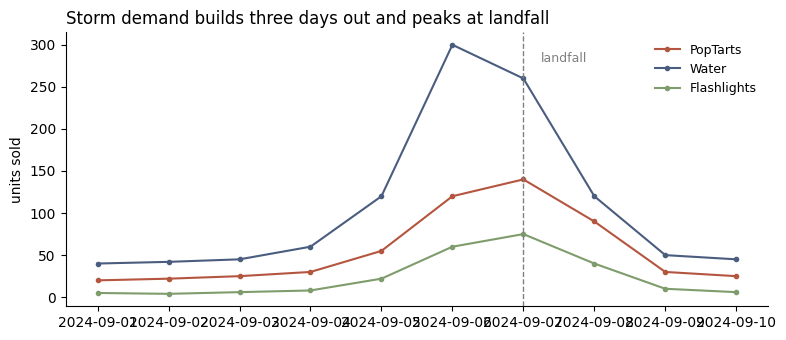

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

               baseline_per_day  surge_per_day  multiple  pct_increase
category                                                              
Breakfast                 71.50         376.86      5.27        427.07
Emergency                352.00        1006.43      2.86        185.92
Electronics               70.00         175.86      2.51        151.22
Entertainment             91.75         228.57      2.49        149.12
Health                    39.75          95.00      2.39        138.99
Alcohol                   58.75         138.86      2.36        136.35
Household                 86.50         176.29      2.04        103.80
Grocery                  176.25         306.57      1.74         73.94
Baby                      84.75         133.71      1.58         57.77
Snacks                    57.75          73.71      1.28         27.64


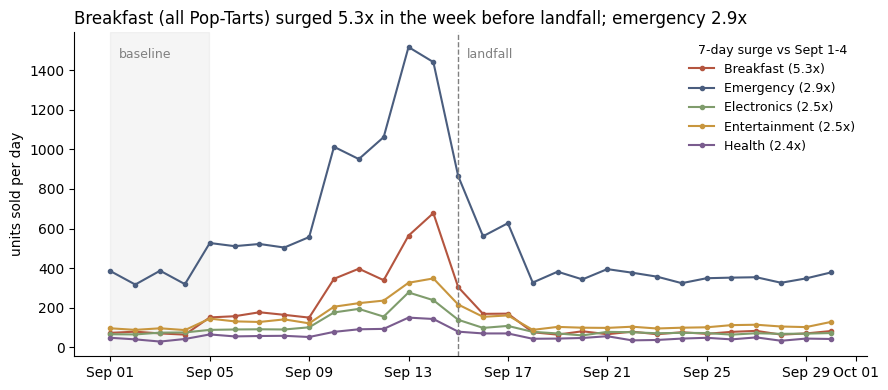

baseline Sept 1-4                : top = Breakfast  5.27x
baseline Sept 1-7                : top = Breakfast  3.42x
baseline Sept 18-30 (post-storm) : top = Breakfast  5.14x


In [3]:
cat_daily = tx.pivot_table(index='date', columns='category', values='quantity',
                           aggfunc='sum', fill_value=0)
cat_surge = surge_table(cat_daily)
print(cat_surge.to_string())

top5 = cat_surge.index[:5]
colors = ['#b4553f', '#4a5d7e', '#7f9c6c', '#c8963e', '#7a5c8e']

fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(top5, colors):
    ax.plot(cat_daily.index, cat_daily[col], marker='o', ms=3, color=color,
            label=f"{col} ({cat_surge.loc[col, 'multiple']:.1f}x)")
ax.axvspan(BASE_START, BASE_END + pd.Timedelta(hours=23), color='gray', alpha=0.08)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(LANDFALL + pd.Timedelta(hours=8), ax.get_ylim()[1] * 0.92),
            fontsize=9, color='gray')
ax.annotate('baseline', xy=(BASE_START + pd.Timedelta(hours=8), ax.get_ylim()[1] * 0.92),
            fontsize=9, color='gray')
ax.set_title('Breakfast (all Pop-Tarts) surged 5.3x in the week before landfall; emergency 2.9x',
             loc='left', fontsize=12)
ax.set_ylabel('units sold per day')
ax.legend(frameon=False, fontsize=9, title='7-day surge vs Sept 1-4', title_fontsize=9)
clean_axes(ax, dates=True)
plt.tight_layout()
plt.show()

# How much the headline depends on the baseline choice
for label, start, end in [('Sept 1-4', '2024-09-01', '2024-09-04'),
                          ('Sept 1-7', '2024-09-01', '2024-09-07'),
                          ('Sept 18-30 (post-storm)', '2024-09-18', '2024-09-30')]:
    m = cat_daily.loc[SURGE_START:SURGE_END].mean() / cat_daily.loc[start:end].mean()
    print(f"baseline {label:24s}: top = {m.idxmax():10s} {m.max():.2f}x")

**Finding.** Breakfast leads at 5.3x (+427%), and it is entirely Pop-Tarts, the only breakfast product in the file. Emergency (+186%), Electronics (+151%), Entertainment (+149%) and Health (+139%) follow. Every top-5 category peaks on Sept 13–14 and drops on landfall day: the buying happens before the storm, not during it. The sensitivity check shows Breakfast stays on top whichever baseline we use, but the multiple runs from 3.4x to 5.3x depending on that choice, so the window has to be stated next to the number.

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

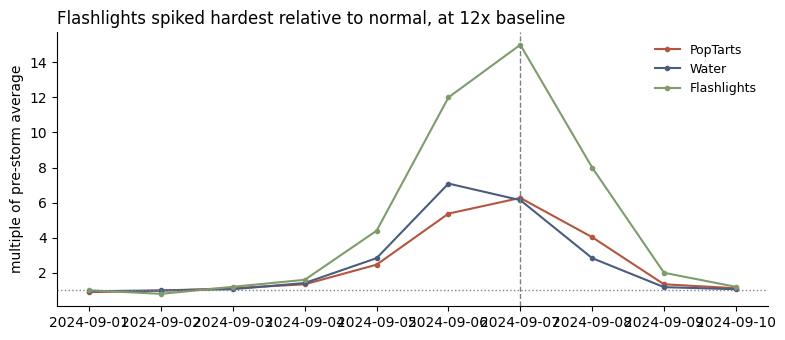

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [4]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

             by_raw_volume           by_multiple
rank                                            
1     Pop-Tarts Strawberry  Pop-Tarts Strawberry
2       Bottled Water 24pk    Bottled Water 24pk
3         AA Batteries 4pk        LED Flashlight
4           LED Flashlight              Monopoly
5        Emergency Candles       Heavy Duty Tarp
6          Heavy Duty Tarp      Portable Charger
7          Light Beer 24pk      AA Batteries 4pk
8                 Monopoly     Emergency Candles

                      baseline_per_day  surge_per_day  multiple
product                                                        
Pop-Tarts Strawberry             71.50         376.86      5.27
Bottled Water 24pk              102.75         320.00      3.11
LED Flashlight                   56.00         168.57      3.01
Monopoly                         37.75         111.43      2.95
Heavy Duty Tarp                  46.00         129.29      2.81
Portable Charger                 40.50         111.14      2.

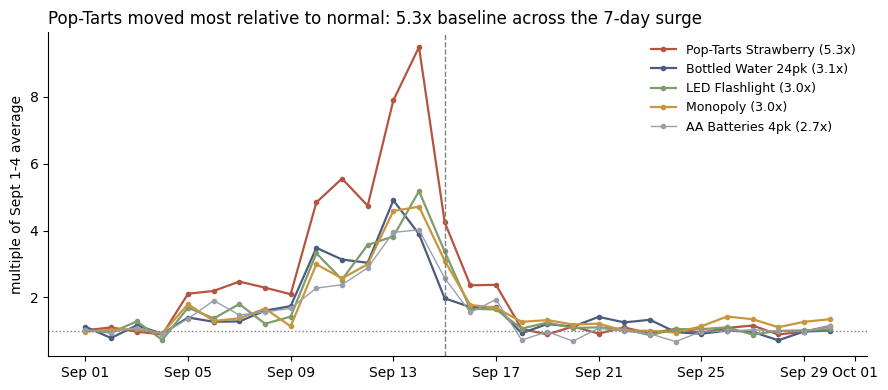

In [5]:
prod_daily = tx.pivot_table(index='date', columns='product', values='quantity',
                            aggfunc='sum', fill_value=0)
prod_surge = surge_table(prod_daily)
prod_surge['extra_units_per_day'] = prod_surge['surge_per_day'] - prod_surge['baseline_per_day']

compare = pd.DataFrame({
    'by_raw_volume': prod_surge.sort_values('extra_units_per_day', ascending=False).index,
    'by_multiple': prod_surge.index,
}, index=pd.RangeIndex(1, len(prod_surge) + 1, name='rank'))
print(compare.head(8).to_string())
print()
print(prod_surge[['baseline_per_day', 'surge_per_day', 'multiple']].to_string())

indexed = prod_daily / prod_daily.loc[BASE_START:BASE_END].mean()
show = list(prod_surge.index[:4]) + ['AA Batteries 4pk']   # batteries: #3 on volume, #7 on multiple

fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(show, ['#b4553f', '#4a5d7e', '#7f9c6c', '#c8963e', '#9aa0aa']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color,
            label=f"{col} ({prod_surge.loc[col, 'multiple']:.1f}x)",
            lw=1 if col == 'AA Batteries 4pk' else 1.6)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.set_title(f"Pop-Tarts moved most relative to normal: {prod_surge.loc['Pop-Tarts Strawberry', 'multiple']:.1f}x "
             f"baseline across the 7-day surge", loc='left', fontsize=12)
ax.set_ylabel('multiple of Sept 1-4 average')
ax.legend(frameon=False, fontsize=9)
clean_axes(ax, dates=True)
plt.tight_layout()
plt.show()

**Does the ranking change?** At the top, no. Pop-Tarts and water rank #1 and #2 on both measures. Below that it shifts. **Monopoly jumps from 8th to 4th** once indexed (2.95x), which is the Question 5 board-games anomaly showing up on its own. AA batteries fall from 3rd to 7th because they already sell a lot on a normal day. On this chart Pop-Tarts reach about 9.5x baseline on Sept 14 alone. For the deck, the raw chart answers "how much to ship" and the indexed chart answers "what is unusual." 

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

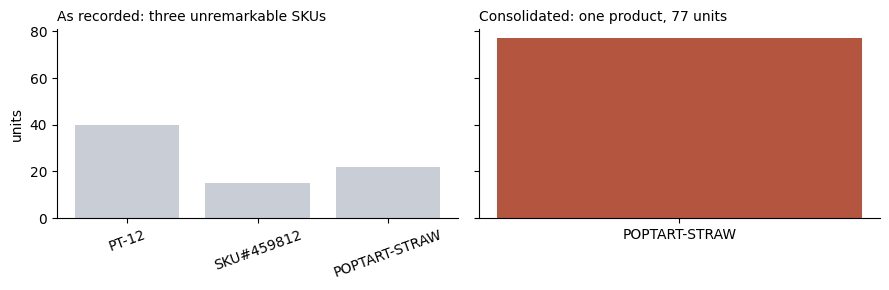

In [6]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

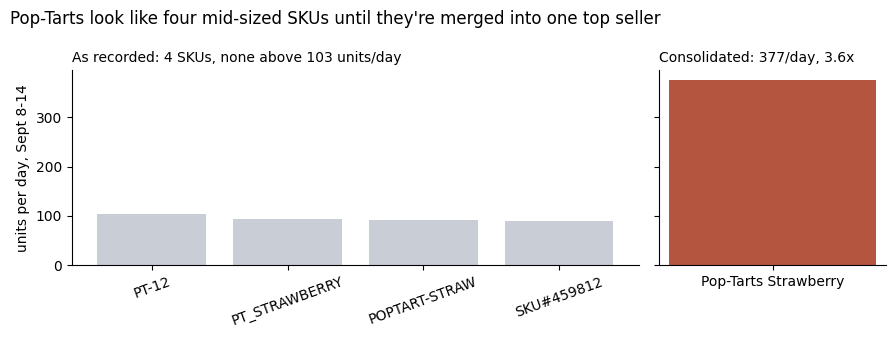

raw SKU x product-name spellings for this one product: 20
largest single SKU PT-12: 103.3 units/day
consolidated: 376.9 units/day -> 3.6x what the biggest fragment shows
surge multiple, consolidated: 5.27x
surge multiple, per SKU:      SKU#459812 6.56x, PT_STRAWBERRY 5.52x, POPTART-STRAW 5.28x, PT-12 4.35x


In [7]:
pop = tx[tx['product'] == 'Pop-Tarts Strawberry']
pop_surge = pop[(pop['date'] >= SURGE_START) & (pop['date'] <= SURGE_END)]

fragmented = pop_surge.groupby('sku')['quantity'].sum().sort_values(ascending=False) / 7
consolidated = pd.Series({'Pop-Tarts Strawberry': fragmented.sum()})
multiple = consolidated.iloc[0] / fragmented.max()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True, gridspec_kw={'width_ratios': [4, 1.6]})
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} SKUs, none above {fragmented.max():.0f} units/day',
                  fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title(f'Consolidated: {consolidated.iloc[0]:.0f}/day, {multiple:.1f}x', fontsize=10, loc='left')
axes[0].set_ylabel('units per day, Sept 8-14')
for ax in axes:
    clean_axes(ax)
fig.suptitle("Pop-Tarts look like four mid-sized SKUs until they're merged into one top seller",
             x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

print(f"raw SKU x product-name spellings for this one product: {pop.groupby(['sku', 'product_name']).ngroups}")
print(f"largest single SKU {fragmented.idxmax()}: {fragmented.max():.1f} units/day")
print(f"consolidated: {consolidated.iloc[0]:.1f} units/day -> {multiple:.1f}x what the biggest fragment shows")
print(f"surge multiple, consolidated: {prod_surge.loc['Pop-Tarts Strawberry', 'multiple']:.2f}x")
print(f"surge multiple, per SKU:      " + ', '.join(
    f"{s} {m:.2f}x" for s, m in surge_table(pop.pivot_table(index='date', columns='sku', values='quantity',
                                                             aggfunc='sum', fill_value=0))['multiple'].items()))

**Business impact.** In the fragmented view, an analyst ranking SKUs by volume sees four ordinary breakfast items at about 90–100 units a day each, and none of them looks like a top seller. A replenishment order sized off the biggest one (PT-12) would cover about 27% of real demand. Consolidated, Pop-Tarts sell 377 units a day in the surge week, **3.6x** the largest fragment, which makes them the highest-volume product in the store (water is next at 320). The surge multiple is also unstable when fragmented. Depending on which SKU you pick you would report anywhere from 4.4x to 6.6x, while the consolidated 5.3x is the one number that holds up.

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

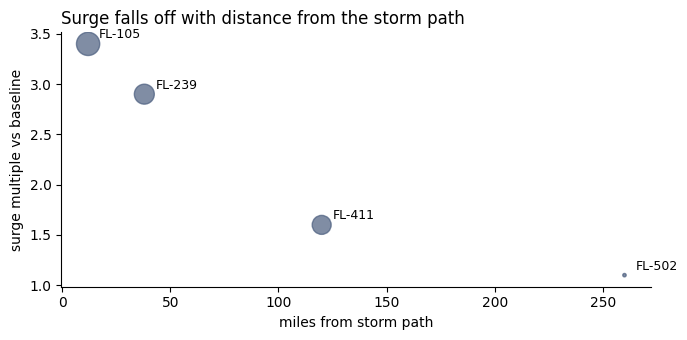

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [8]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

                    city      region  miles_from_orlando  baseline_per_day  surge_per_day  multiple peak_day  transactions  coords_filled
store_id                                                                                                                                 
FL-239           Orlando     Central                 0.0             89.50         209.57      2.34   Sep 13          2010          False
FL-287         Kissimmee     Central                17.0             90.00         220.14      2.45   Sep 14          2053          False
FL-302          Lakeland     Central                49.0             97.75         239.43      2.45   Sep 14          2123          False
FL-156     Daytona Beach        East                51.0             94.25         229.14      2.43   Sep 13          2074          False
FL-105             Tampa        West                77.0             91.50         231.71      2.53   Sep 14          2043          False
FL-445    St. Petersburg        We

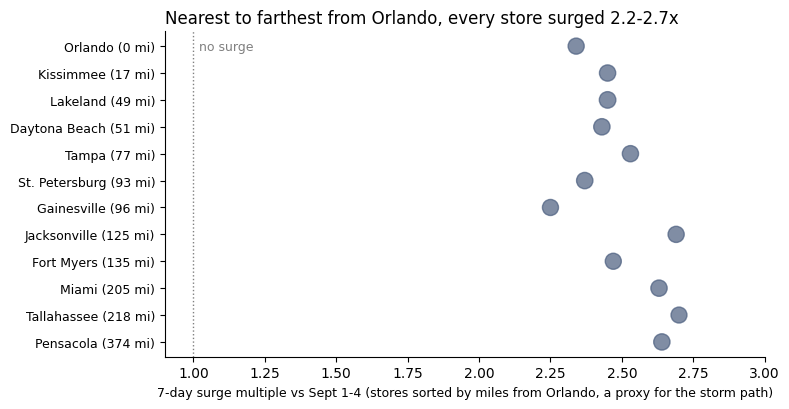

multiple spread: 2.25-2.70x, largest |z| = 1.7 (FL-078)
peak days: {'Sep 13': 6, 'Sep 14': 6}


In [9]:
stores = pd.read_csv(f'{DATA}/store_locations.csv', dtype={'store_id': str})
stores['store_id'] = norm_store(stores['store_id'])
stores = stores.drop_duplicates(subset='store_id')
assert stores['store_id'].is_unique and len(stores) == 12

# FL-619 (Tallahassee) has no coordinates in the file; fill from the city's public lat/lon and flag it.
missing = stores['latitude'].isna()
stores.loc[stores['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
stores['coords_filled'] = missing

# No storm track ships with the data, so distance from Orlando (where the case is set and the
# distance the DC table measures to) stands in for "distance from the path".
ORLANDO = (28.5383, -81.3792)
def miles(lat, lon, lat0=ORLANDO[0], lon0=ORLANDO[1]):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))
stores['miles_from_orlando'] = miles(stores['latitude'], stores['longitude']).round(0)

store_daily = tx.pivot_table(index='date', columns='store_id', values='quantity', aggfunc='sum', fill_value=0)
by_store = (surge_table(store_daily)
            .join(tx.groupby('store_id').size().rename('transactions'))
            .join(store_daily.idxmax().dt.strftime('%b %d').rename('peak_day'))
            .join(stores.set_index('store_id')[['city', 'region', 'miles_from_orlando', 'coords_filled']],
                  validate='one_to_one')
            .sort_values('miles_from_orlando'))
print(by_store[['city', 'region', 'miles_from_orlando', 'baseline_per_day', 'surge_per_day',
                'multiple', 'peak_day', 'transactions', 'coords_filled']].to_string())

# Stores listed nearest to farthest: a distance gradient would show up as a slant.
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(by_store))[::-1]
ax.scatter(by_store['multiple'], y, s=by_store['transactions'] / 15, alpha=0.7, color='#4a5d7e')
ax.set_yticks(y, [f'{r.city} ({r.miles_from_orlando:.0f} mi)' for r in by_store.itertuples()], fontsize=9)
ax.axvline(1.0, ls=':', color='gray', lw=1)
ax.annotate('no surge', xy=(1.02, y.max()), fontsize=9, color='gray', va='center')
ax.set_xlim(0.9, 3.0)
ax.set_title(f"Nearest to farthest from Orlando, every store surged "
             f"{by_store['multiple'].min():.1f}-{by_store['multiple'].max():.1f}x", loc='left', fontsize=12)
ax.set_xlabel('7-day surge multiple vs Sept 1-4 (stores sorted by miles from Orlando, a proxy for the storm path)',
              fontsize=9)
clean_axes(ax)
plt.tight_layout()
plt.show()

z = (by_store['multiple'] - by_store['multiple'].mean()) / by_store['multiple'].std()
print(f"multiple spread: {by_store['multiple'].min():.2f}-{by_store['multiple'].max():.2f}x, "
      f"largest |z| = {z.abs().max():.1f} ({z.abs().idxmax()})")
print('peak days:', by_store['peak_day'].value_counts().to_dict())

**Finding.** We plotted this as a sorted dot plot rather than a scatter with a fit line. With twelve stores of similar size (about 2,000 transactions each, so the bubbles are all about the same and every point is equally trustworthy) a regression line would only invite questions it can't answer. The pattern is flat. Every store surged between 2.25x and 2.70x, and every store peaked on Sept 13 or 14 (six on each day), so no store surged earlier than the rest. If anything the far stores run slightly higher: Pensacola, 374 miles out, is at 2.64x while Orlando itself is at 2.34x. That is the opposite of the hypothesis, and the gap is too small to argue from. Nothing is an outlier either. The largest z-score is 1.7 (Gainesville, the low end). So the honest Q4 answer for this data is a statewide, simultaneous surge, not a gradient by distance. Two caveats belong on the slide. First, distance from Orlando stands in for the storm path, because the data has no track. Second, Tallahassee's coordinates were missing and were filled from the city's public lat/lon.

### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [10]:
# Checkpoint
top_product = prod_surge.index[0]                       # Pop-Tarts Strawberry (all 4 SKUs consolidated)
surge_multiple = round(prod_surge['multiple'].iloc[0], 2)
baseline_window = 'Sept 1-4, 2024 (4 days before the first step-up on Sept 5); surge = Sept 8-14, the 7 days before Sept 15 landfall'
charts_ready = 4                                        # category trend, indexed products, Pop-Tart before/after, stores

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Pop-Tarts Strawberry
surge multiple: 5.27
baseline window: Sept 1-4, 2024 (4 days before the first step-up on Sept 5); surge = Sept 8-14, the 7 days before Sept 15 landfall
charts ready: 4
